### HW2: ML for materials science

In [1]:
import matplotlib.pyplot as plt

In [3]:
# download data
!mkdir data
!wget -O./data/train.dat https://raw.githubusercontent.com/dembart/intro-to-materials-informatics/refs/heads/main/data/hw2/train.dat

--2026-10-17 09:50:34--  https://raw.githubusercontent.com/dembart/intro-to-materials-informatics/refs/heads/main/data/hw2/train.dat
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15144 (15K) [text/plain]
Saving to: ‘./data/train.dat’

./data/train.dat    100%[===================>]  14.79K  --.-KB/s    in 0.001s  

2026-10-17 09:50:34 (9.99 MB/s) - ‘./data/train.dat’ saved [15144/15144]



### Task 1: StandardScaler (5 points)

Write a function that scales the input feature matrix X using numpy. Compare your solution with scipy.stats.zscore method

In [7]:
import numpy as np
from scipy.stats import zscore

def CustomStandardScaler(X):

    """
    Performs Z-score normalization of the given matrix

    Params
    ------
    X: np.array
        matrix of shape (N, M) where each column
        corresponds to the feature vector

    Returns
    -------
    Scaled matrix

    """

    return (X - X.mean(axis = 0)) / X.std(axis = 0)


X = np.random.randint(-30, 217,(100, 600))
CustomStandardScaler(X)

array([[ 0.30595816,  1.68679056,  0.90235312, ...,  0.48517296,
        -1.50782284,  1.3640414 ],
       [-1.16168256, -0.09440327,  1.43200123, ...,  1.1545694 ,
        -1.10669945,  1.39042773],
       [ 1.44412852,  0.27667878,  1.66894907, ...,  1.16851516,
        -1.07995789,  1.29807557],
       ...,
       [ 0.38083779, -0.68813455, -1.42531094, ..., -1.28593845,
        -0.58523903, -1.15585324],
       [ 1.42915259,  1.62741743,  1.01385799, ..., -1.71825699,
         0.43094023,  1.35084823],
       [-0.81723627,  0.27667878, -1.03504391, ...,  1.37770155,
         0.51116491, -0.60174029]])

### Task 2: Coulomb matrix (5 points)

One of the ways of representing a molecular structure is a Coulomb matrix. Write a function that takes a molecule as an input and returns its Coulomb matrix (M) encoding

\begin{split}\begin{equation}
M_{ij}^\mathrm{Coulomb}=\left\{
    \begin{matrix}
    0.5 Z_i^{2.4} & \text{for } i = j \\
        \frac{Z_i Z_j}{R_{ij}} & \text{for } i \neq j
    \end{matrix}
    \right.
\end{equation}\end{split}

$Z$ - atomic number

$R_i$ - position of an atom i


Compare your results with the dscribe pyhton package

https://singroup.github.io/dscribe/latest/tutorials/descriptors/coulomb_matrix.html



In [15]:
def coulomb_matrix(atoms):
    """
    This function calculates a Coulomb matrix for a given
    molecular structure

    Params
    ------
    atoms: ase's Atoms object
        molecule

    Returns
    -------
    coulombic matrix of shape (N, N), where N is the number of atoms in the structure
    """

    n_atoms = len(atoms)
    Z = atoms.numbers

    R = atoms.get_all_distances()

    R_safe = np.copy(R)
    np.fill_diagonal(R_safe, 1.0)

    matrix = np.outer(Z, Z) / R_safe

    indices = np.arange(n_atoms)
    matrix[indices, indices] = 0.5 * (Z ** 2.4)

    return matrix

In [16]:
!pip install ase

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 31.4 MB/s eta 0:00:00


In [19]:

!pip install dscribe -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 773.7/773.7 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 11.4 MB/s eta 0:00:00


In [24]:
from ase.build import molecule
from dscribe.descriptors import CoulombMatrix

water = molecule('H2O')

custom_cm = coulomb_matrix(water)
print("Custom Coulomb Matrix:")
print(custom_cm)

cm_descriptor = CoulombMatrix(n_atoms_max=3, permutation='none')
dscribe_cm = cm_descriptor.create(water).reshape((3, 3))
print("DScribe Coulomb Matrix:")
print(dscribe_cm)

difference = np.abs(custom_cm - dscribe_cm).max()
print(f"max diff: {difference:.1e}")

Custom Coulomb Matrix:
[[73.51669472  8.25964169  8.25964169]
 [ 8.25964169  0.5         0.65510279]
 [ 8.25964169  0.65510279  0.5       ]]
DScribe Coulomb Matrix:
[[73.51669472  8.25964169  8.25964169]
 [ 8.25964169  0.5         0.65510279]
 [ 8.25964169  0.65510279  0.5       ]]
max diff: 0.0e+00


### Task 3: Bootstrapping (5 points)

Demonstrate that for a dataset of $n$ samples, the expected proportion of unique instances in a bootstrap sample converges to $t = (1-1/e)$ for $n >> 1$

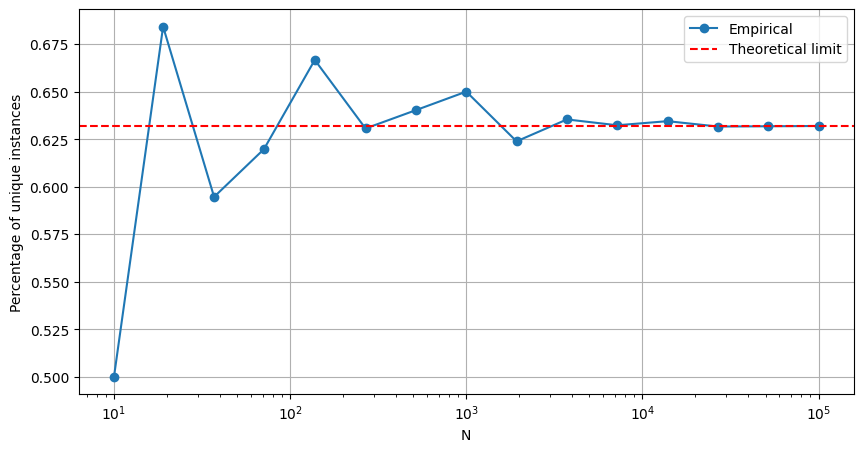

In [32]:
import numpy as np
import matplotlib.pyplot as plt


n = np.logspace(1, 5, 15, dtype=int)
proportions = []

for num in n:
    data = np.arange(num)
    bootstrap = np.random.choice(data, size=num, replace=True)

    unique_count = len(np.unique(bootstrap))
    proportions.append(unique_count / num)


plt.figure(figsize=(10, 5))
plt.plot(n, proportions, 'o-', label='Empirical')
plt.axhline(1 - 1/np.e, color='r', linestyle='--', label='Theoretical limit')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('Percentage of unique instances')
plt.legend()
plt.grid(True)
plt.show()

### Task 4: Hardness dataset

Given a hardness dataset (data/train.dat). The target property is stored in a 'property' column.

Features descirption is given in the original paper
https://arxiv.org/pdf/2304.12880


#### Part 1: (10 points)
- Perform EDA for the dataset

- Drop non-numerical columns

- Drop nearly collinear features ($R_p$ > 0.95) (done for you)

- Calculate a correlation matrix for the dataset

- Plot barplot for $R_p$(feature_i, target)

- Report top5 features that have the highest correlation with the target property



- What are these features? Explain why they have a strong correlation






In [33]:
import pandas as pd
import numpy as np

data = pd.read_csv('data/train.dat', sep = '\s+')


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_4221/3245138967.py:4: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('data/train.dat', sep = '\s+')


In [36]:
def remove_collinear_features(x, threshold):

    # source: https://www.kaggle.com/code/oldwine357/removing-highly-correlated-features/notebook
    """
    Objective:
        Remove collinear features in a dataframe with a correlation coefficient
        greater than the threshold. Removing collinear features can help a model
        to generalize and improves the interpretability of the model.

    Inputs:
        x: features dataframe
        threshold: features with correlations greater than this value are removed

    Output:
        dataframe that contains only the non-highly-collinear features
    """

    # Calculate the correlation matrix
    corr_matrix = x.corr()
    iters = range(len(corr_matrix.columns) - 1)
    drop_cols = []

    # Iterate through the correlation matrix and compare correlations
    for i in iters:
        for j in range(i+1):
            item = corr_matrix.iloc[j:(j+1), (i+1):(i+2)]
            col = item.columns
            row = item.index
            val = abs(item.values)

            # If correlation exceeds the threshold
            if val >= threshold:
                # Print the correlated features and the correlation value
                #print(col.values[0], "|", row.values[0], "|", round(val[0][0], 2))
                drop_cols.append(col.values[0])

    # Drop one of each pair of correlated columns
    drops = set(drop_cols)
    x = x.drop(columns=drops)
    print('Removed Columns {}'.format(drops))
    return x

In [40]:
# drop collinear features

threshold = 0.95
X = remove_collinear_features(data.drop(['property', 'materials'], axis = 1), threshold)


Removed Columns {'BV', 'Gr', 'Br', 'Y', 'GV'}


In [46]:
pd.set_option('display.max_columns', 21)

In [47]:
data.drop(columns=['materials']).corr()

,property,D,Bv,Br,BV,Gv,Gr,GV,el,pr,Y,Fr,Rx,Rn,RW,Ax,An,AW,IEx,IEn,IEW
property,1.000000,0.258021,0.709283,0.707846,0.708699,0.869511,0.867554,0.868567,-0.373735,-0.595878,0.849059,0.656326,0.010693,-0.165277,-0.072826,0.053131,-0.530936,-0.145795,-0.088826,0.036807,-0.158371
D,0.258021,1.000000,0.601554,0.605496,0.603553,0.384561,0.375130,0.380175,-0.164039,0.108529,0.429273,0.040092,0.646642,0.085919,0.564243,0.901085,-0.243527,0.794581,-0.253096,0.136215,-0.216583
Bv,0.709283,0.601554,1.000000,0.999456,0.999851,0.885456,0.875579,0.881361,-0.427214,-0.245886,0.917535,0.359722,0.414456,-0.213729,0.213360,0.324443,-0.699027,0.071770,-0.141296,-0.043168,-0.209847
Br,0.707846,0.605496,0.999456,1.000000,0.999870,0.882529,0.873242,0.878727,-0.433954,-0.240502,0.915334,0.363587,0.415232,-0.213885,0.220526,0.326238,-0.698744,0.077853,-0.140362,-0.043719,-0.210622
BV,0.708699,0.603553,0.999851,0.999870,1.000000,0.883992,0.874401,0.880040,-0.430464,-0.242664,0.916438,0.362284,0.415113,-0.214010,0.217135,0.325257,-0.698844,0.074896,-0.140520,-0.043519,-0.209953
Gv,0.869511,0.384561,0.885456,0.882529,0.883992,1.000000,0.997811,0.999453,-0.473452,-0.594807,0.996317,0.510424,0.235479,-0.091988,0.096534,0.151694,-0.630151,-0.107889,-0.232706,-0.034336,-0.294727
Gr,0.867554,0.375130,0.875579,0.873242,0.874401,0.997811,1.000000,0.999431,-0.519512,-0.603288,0.994815,0.511214,0.232698,-0.083694,0.106866,0.142434,-0.624446,-0.108529,-0.240331,-0.034029,-0.303014
GV,0.868567,0.380175,0.881361,0.878727,0.880040,0.999453,0.999431,1.000000,-0.496613,-0.598583,0.996179,0.511038,0.234786,-0.088149,0.101627,0.147229,-0.627972,-0.108466,-0.236704,-0.034908,-0.299006
el,-0.373735,-0.164039,-0.427214,-0.433954,-0.430464,-0.473452,-0.519512,-0.496613,1.000000,0.287976,-0.496904,-0.138714,-0.216389,0.017402,-0.269369,-0.019188,0.435855,0.065961,0.185598,0.136868,0.297290
pr,-0.595878,0.108529,-0.245886,-0.240502,-0.242664,-0.594807,-0.603288,-0.598583,0.287976,1.000000,-0.551378,-0.284792,0.165443,-0.100838,0.130609,0.214081,0.304632,0.362917,0.254928,0.107500,0.302574


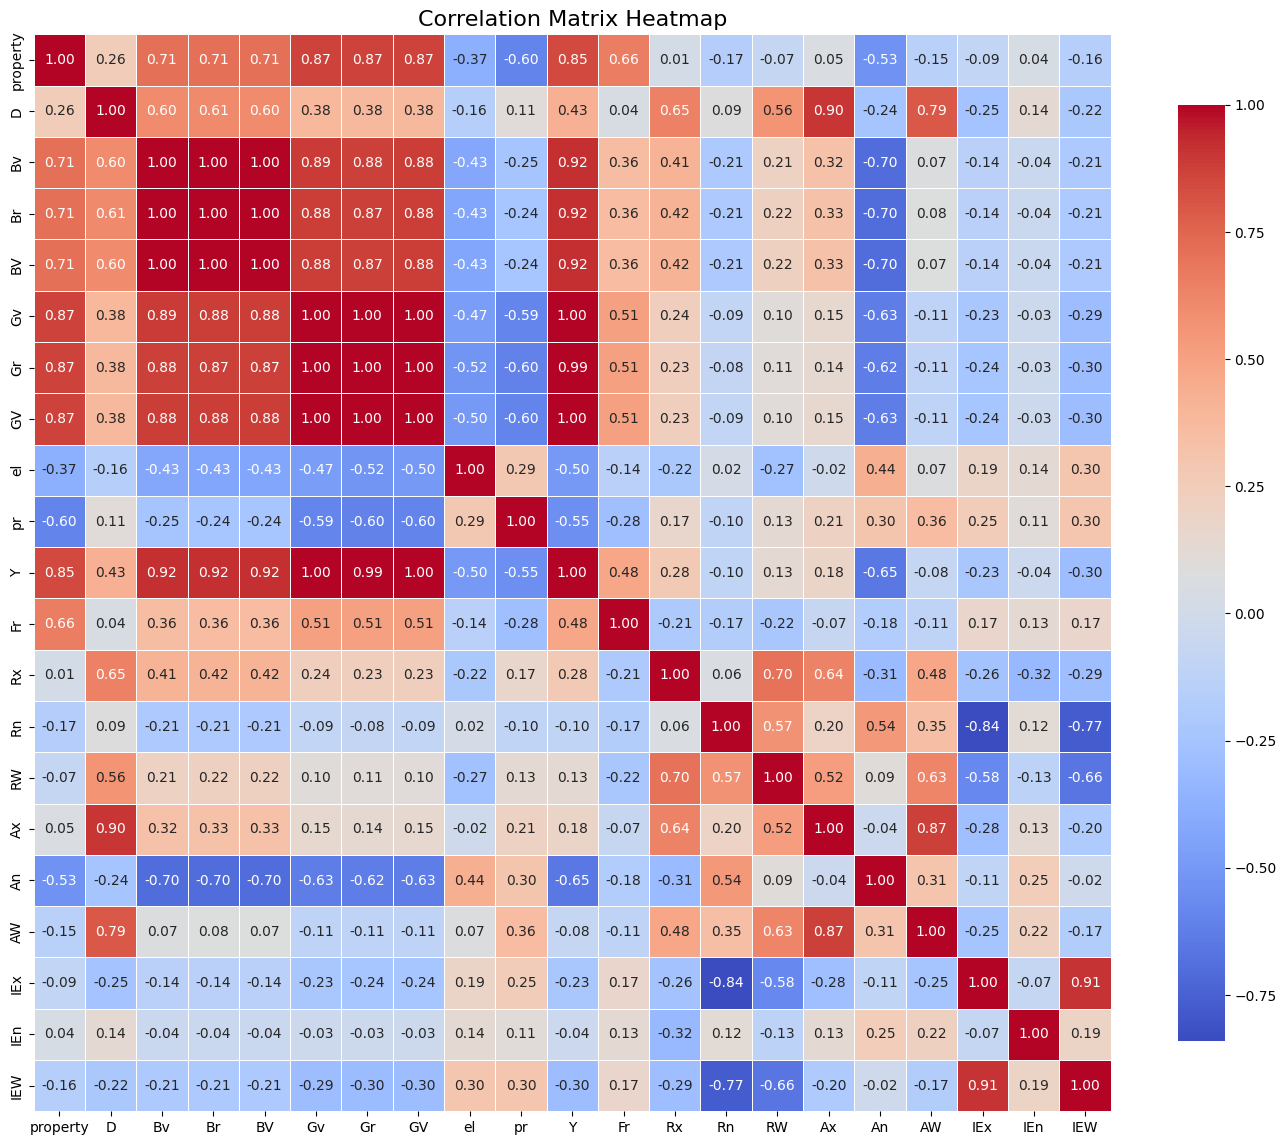

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = data.drop(columns=['materials']).corr()
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

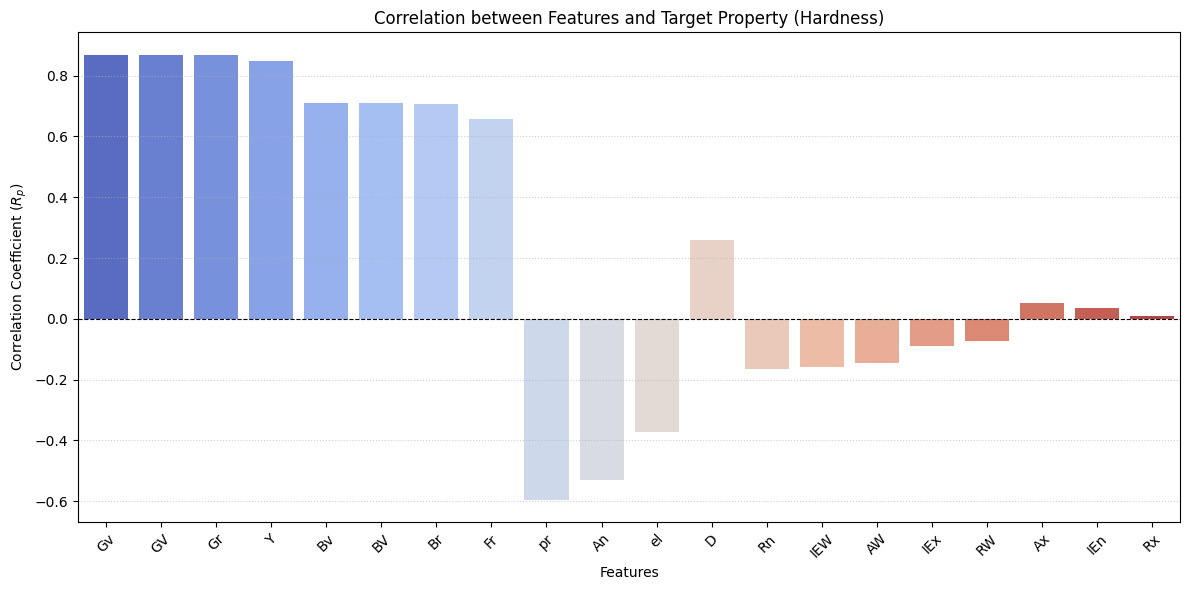

Top 5 features with the highest correlation with target:
Gv: absolute correlation = 0.8695
GV: absolute correlation = 0.8686
Gr: absolute correlation = 0.8676
Y: absolute correlation = 0.8491
Bv: absolute correlation = 0.7093


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


features_corr = data.drop(columns=['materials', 'property']).corrwith(data['property'])

sorted_corr = features_corr.reindex(features_corr.abs().sort_values(ascending=False).index)


plt.figure(figsize=(12, 6))
sns.barplot(x=sorted_corr.index, y=sorted_corr.values, palette='coolwarm', hue=sorted_corr.index, legend=False)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient ($R_p$)')
plt.title('Correlation between Features and Target Property (Hardness)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


top_5 = sorted_corr.abs().head(5)
print("Top 5 features with the highest correlation with target:")
for feature, val in top_5.items():
    sign = "+" if sorted_corr[feature] >= 0 else "-"
    print(f"{feature}: absolute correlation = {val:.4f}")

These features have highest correlation with the target because they directly represent the elastic moduli (Shear modulus G, Young's modulus Y, and Bulk modulus B) of the materials:

1. Shear modulus ($G_v, G_V, G_r$) measures the resistance of a material to shear deformation. Since plastic deformation and dislocation movement (which determine hardness) occur via shear processes, $G$ is physically the most critical descriptor for hardness.
2. Young's modulus ($Y$) reflects the overall stiffness and strength of chemical bonds in the crystal lattice. Stronger bonds make it harder to locally deform the material.
3. Bulk modulus ($B_v$) resists volume compression under pressure, correlating with the energy of chemical bonds. Materials with high bulk modulus strongly resist indentation.

#### Part 2: (20 points)

- Split your data set into train/test data splits with a ```test_size = 0.3```. Report a random seed used!
- Fit at least 4 different regression models (e.g. SVR, KRR, RF, KNN regressor, AdaBoost) and report test metrics

- For two these models perform a grid search optimization of hyperparameters using KFold cross validation

- Perform feature importance study. What features are the most important?

- Perform forward feature selection. Plot MSE (or other metric) vs. # features

- How many features are enough? Can we get a better perfomance with less features?

In [57]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
# from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.neighbors import KNeighborsRegressor
import numpy as np






In [71]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error


X_temp, X_test, y_temp, y_test = train_test_split(X, data['property'], test_size=0.3, random_state=0)


X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2857, random_state=0)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)



models = {
    'SVR': SVR(C=10, gamma='scale'),
    'KernelRidge': KernelRidge(alpha=1.0, kernel='rbf'),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

print("Baseline Models Performance on Validation Set:")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds_val = model.predict(X_val_scaled)

    r2 = r2_score(y_val, preds_val)
    mse = mean_squared_error(y_val, preds_val)
    print(f"{name:12}  R2 Score: {r2:.4f}  MSE: {mse:.4f}")

Baseline Models Performance on Validation Set:
SVR           R2 Score: 0.6348  MSE: 38.7998
KernelRidge   R2 Score: 0.7191  MSE: 29.8392
RandomForest  R2 Score: 0.7632  MSE: 25.1585
KNN           R2 Score: 0.7019  MSE: 31.6699


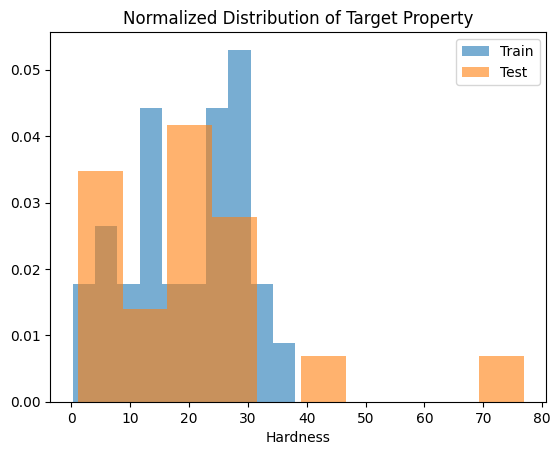

In [72]:
plt.hist(y_train, density=True, alpha=0.6, label='Train', bins=10)
plt.hist(y_test, density=True, alpha=0.6, label='Test', bins=10)
plt.xlabel('Hardness')
plt.title('Normalized Distribution of Target Property')
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import KFold, GridSearchCV
import numpy as np

X_train_val = np.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])

scaler_cv = StandardScaler()
X_train_val_scaled = scaler_cv.fit_transform(X_train_val)
X_test_scaled = scaler_cv.transform(X_test)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

krr_param_grid = {
    'alpha': [1e-4, 1e-3, 1e-2, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0],
    'kernel': ['rbf', 'laplacian'],
    'gamma': np.logspace(-4, 2, 10)
}
krr_grid = GridSearchCV(KernelRidge(), param_grid=krr_param_grid, cv=kfold, scoring='r2', n_jobs=-1)
krr_grid.fit(X_train_val_scaled, y_train_val)


rf_param_grid = {
    'n_estimators': [100, 200, 300, 500, 700],
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 3, 5, 8, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid=rf_param_grid, cv=kfold, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train_val_scaled, y_train_val)

print("Best KernelRidge parameters:", krr_grid.best_params_)
print(f"Best KernelRidge R2 (CV): {krr_grid.best_score_:.4f}")
print("\nBest RF parameters:", rf_grid.best_params_)
print(f"Best RF R2 (CV): {rf_grid.best_score_:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [ ]:
# get r2_score and MSE

(0.7173728464477753, 4.488134584123709)

In [ ]:

best_model = krr_grid.best_estimator_ if krr_grid.best_score_ > rf_grid.best_score_ else rf_grid.best_estimator_
print(f"Selected best model: {best_model}")

# Делаем предсказания на независимом тестовом множестве
preds_test = best_model.predict(X_test_scaled)

test_r2 = r2_score(y_test, preds_test)
test_mse = mean_squared_error(y_test, preds_test)

print(f"\nPerformance on Test Set:")
print(f"R2 Score: {test_r2:.4f}")
print(f"MSE: {test_mse:.4f}")

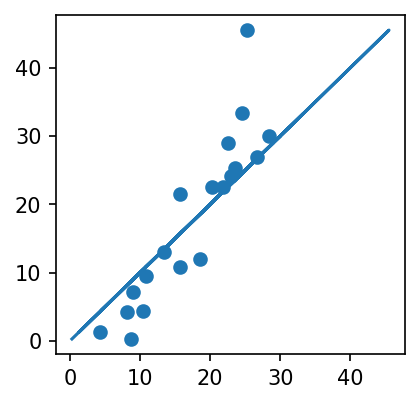

In [ ]:
# plot y_test vs. predictions


In [ ]:
# Строим график зависимости истинных значений от предсказанных
plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds_svr, color='blue', alpha=0.6, label='Predicted vs True')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal prediction')
plt.xlabel('True Hardness')
plt.ylabel('Predicted Hardness')
plt.title('True vs Predicted Hardness (Optimized SVR)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Perform forward feature selection
# You can use mlxtend library (or function from the seminar)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done  15 out of  15 | elapsed:    0.1s finished
Features: 1/15[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done  14 out of  14 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished
Features: 2/15[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done  13 out of  13 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s finished
Features: 3/15[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done  12 out of  12 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Using backend SequentialBacken

In [ ]:
# Реализуем пошаговый отбор признаков вручную (Forward Feature Selection)
# Оценивать будем лучшую модель SVR с помощью кросс-валидации
from sklearn.model_selection import cross_val_score

remaining_features = list(X.columns)
selected_features = []
best_scores_by_step = []

for i in range(len(X.columns)):
    step_scores = []
    for feature in remaining_features:
        candidate_features = selected_features + [feature]
        # Отбор на тренировочном наборе
        X_subset = X_train_scaled[:, [X.columns.get_loc(f) for f in candidate_features]]
        scores = cross_val_score(SVR(C=svr_grid.best_params_['C'], gamma=svr_grid.best_params_['gamma']), X_subset, y_train, cv=5, scoring='neg_mean_squared_error')
        step_scores.append((np.mean(scores), feature))

    # Сортируем и выбираем лучший признак на этом шаге
    step_scores.sort(reverse=True) # neg_mean_squared_error чем выше (ближе к 0), тем лучше
    best_score, best_feature = step_scores[0]

    selected_features.append(best_feature)
    remaining_features.remove(best_feature)
    best_scores_by_step.append(-best_score) # сохраняем положительный MSE

    print(f"Step {i+1}: Added {best_feature:10} | CV MSE: {-best_score:.4f}")

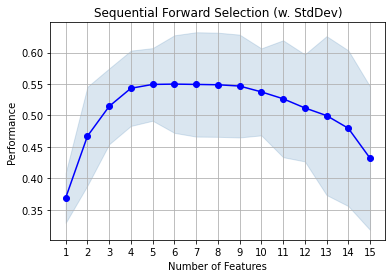

In [ ]:
# plot MSE vs. # of features (you can use mlxtend library)

In [ ]:
# График зависимости MSE от количества признаков
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(best_scores_by_step) + 1), best_scores_by_step, 'o-', color='green', lw=2)
plt.xlabel('Number of Features')
plt.ylabel('CV Mean Squared Error')
plt.title('Forward Feature Selection: MSE vs Number of Features')
plt.grid(True)
plt.show()

In [ ]:
# refit model on the selected features

In [ ]:
# Переобучаем модель на оптимальном количестве признаков (например, топ-5 признаков)
optimal_n = 5  # Можно скорректировать по графику выше
optimal_features = selected_features[:optimal_n]

# Индексы признаков
opt_feature_indices = [X.columns.get_loc(f) for f in optimal_features]

X_train_opt = X_train_scaled[:, opt_feature_indices]
X_test_opt = X_test_scaled[:, opt_feature_indices]

# Рефит модели
refitted_model = SVR(C=svr_grid.best_params_['C'], gamma=svr_grid.best_params_['gamma'])
refitted_model.fit(X_train_opt, y_train)
preds_opt = refitted_model.predict(X_test_opt)

In [ ]:
# Вычисляем и выводим метрику R2 для переобученной модели на оптимальных признаках
opt_r2 = r2_score(y_test, preds_opt)
opt_mse = mean_squared_error(y_test, preds_opt)
print(f"Refitted SVR with {optimal_n} features - R2: {opt_r2:.4f}, MSE: {opt_mse:.4f}")

0.7846440238792973

(0.7846440238792973, 3.4985736741294473)

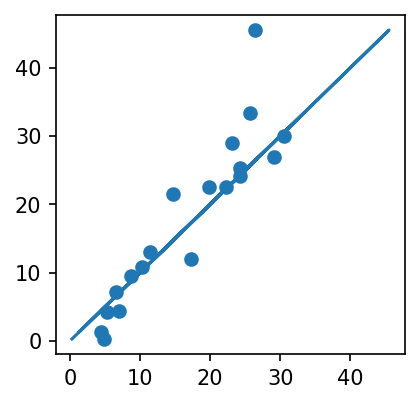

In [ ]:
# plot y_test vs. predictions

In [ ]:
# What are the features?

In [ ]:
# Выводим наиболее важные признаки и результаты рефита
print(f"Selected optimal features: {optimal_features}")
refit_r2 = r2_score(y_test, preds_opt)
refit_mse = mean_squared_error(y_test, preds_opt)
print(f"\nRefitted Model Metrics:")
print(f"R2 Score: {refit_r2:.4f}")
print(f"MSE: {refit_mse:.4f}")

### Task 5: MLMD (20 points)


- Upload a crystal structure of Li10Ge(PS6)2 from the Materials project. Report the mp-id used.

- Perform molecular dynamics study of Li-ion conductivity in the structure. For this:

    - Create a supercell with n_atoms >= 200

    - Perform NVT diffusion runs at T = 800, 1000, 1200 K
        - Using ASE

        - SevenNet universal interatomic potential (or any other)

    - Calculate the Li-ion mean squared displacements as a function of time for each run

    - Extract D vs. T data

    - Fit a line to log(D) vs. 1/T data

    - Report $D_0$ and $E_a$ of the fitted Arrhenius equation

    - Compare calculated values with the literatute




In [ ]:
# === your code ===

### Task 6: MLP Classifier (10 points)
- Train an MLPClassifier

- Plot the decision boundary for the trained model

- Achieve at least 95% accuracy on the test set

/Users/artemdembitskiy/opt/anaconda3/lib/python3.8/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


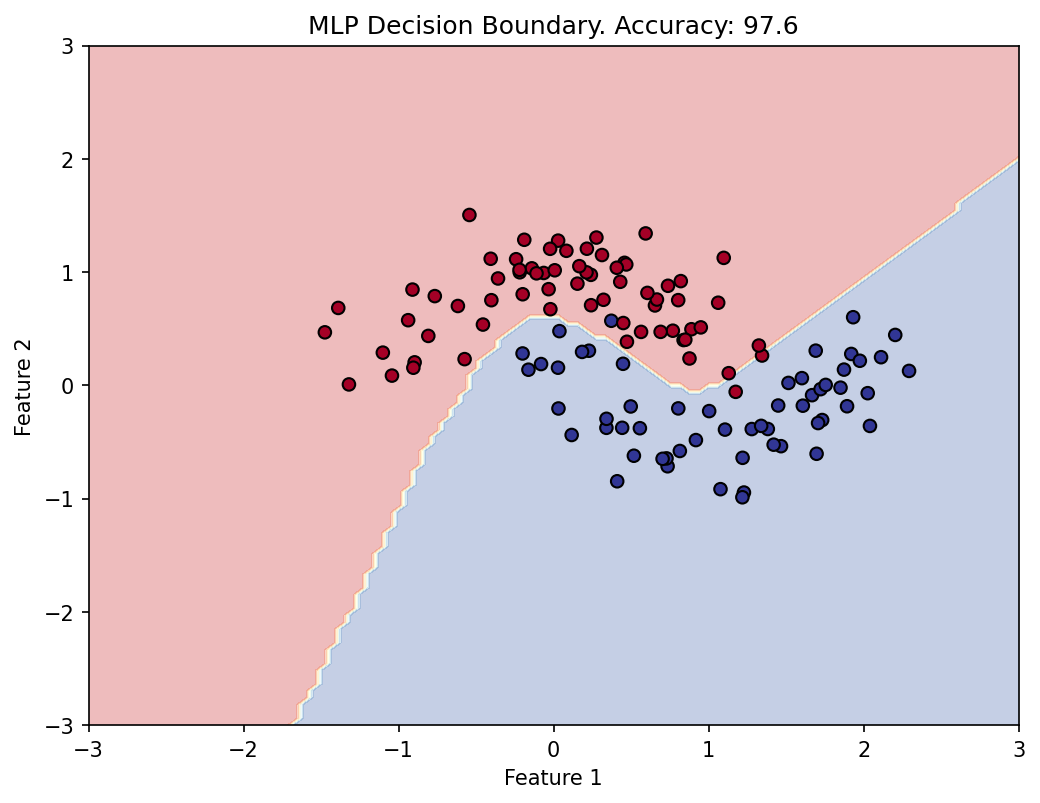

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split


X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y)

# ===== your code =====